#  E23CSEU0373_Assignment – 8


In [1]:
!pip install -q pandas numpy matplotlib seaborn wordcloud nltk scikit-learn pyLDAvis


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from wordcloud import WordCloud

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

import pyLDAvis
import pyLDAvis.lda_model


In [3]:
DATA_URL = 'https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Health_Related_Headlines_Dataset.csv'

try:
    df = pd.read_csv(DATA_URL)
except Exception as e:
    print('Direct download failed.')
    raise e

print('Dataset shape:', df.shape)
print('\nColumns:', list(df.columns))
display(df.head())

Dataset shape: (39405, 5)

Columns: ['Date', 'Source', 'Headlines', 'Teaser', 'Category']


,Date,Source,Headlines,Teaser,Category
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Immunization
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Substance Abuse and Addiction
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Substance Abuse and Addiction
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Substance Abuse and Addiction
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Pain Management


In [4]:
# Basic inspection
print('Missing values:')
display(df.isnull().sum())

print('\nDataset information:')
df.info()

print('\nCategory distribution:')
if 'Category' in df.columns:
    display(df['Category'].value_counts())

Missing values:


Date         0
Source       0
Headlines    0
Teaser       0
Category     0
dtype: int64


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 39405 entries, 0 to 39404
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Date       39405 non-null  str  
 1   Source     39405 non-null  str  
 2   Headlines  39405 non-null  str  
 3   Teaser     39405 non-null  str  
 4   Category   39405 non-null  str  
dtypes: str(5)
memory usage: 1.5 MB

Category distribution:


Category
Clinical Trial                   9331
Pain Management                  9195
Substance Abuse and Addiction    6775
Patient Safety                   5911
Adverse Drug Event               4118
Immunization                     2729
Antibiotic Resistance            1346
Name: count, dtype: int64

# Task 1 – Data Preprocessing and Cleaning



In [5]:
# Use the Headlines column required for the headline-based NLP analysis.
text_column = 'Headlines'

if text_column not in df.columns:
    # Fallback for minor column-name differences
    possible = [c for c in df.columns if c.lower() in ['headline', 'headlines', 'title', 'text']]
    if not possible:
        raise ValueError(f'Could not find a headline/text column. Available columns: {list(df.columns)}')
    text_column = possible[0]

print('Text column used:', text_column)

Text column used: Headlines


In [6]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Additional common headline words can be removed to make topic results more meaningful.
custom_stopwords = {'said', 'says', 'say', 'new', 'health', 'study', 'people'}
stop_words.update(custom_stopwords)

def clean_text(text):
    # Handle missing values
    text = '' if pd.isna(text) else str(text)
    
    # Lowercasing
    text = text.lower()
    
    # Remove URLs and punctuation/numbers
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    
    # Tokenization
    tokens = word_tokenize(text)
    
    # Stop-word removal + lemmatization
    tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 2
    ]
    
    return ' '.join(tokens)

# Apply preprocessing
df['Cleaned_Text'] = df[text_column].apply(clean_text)

print('Cleaning completed.')
display(df[[text_column, 'Cleaned_Text']].head(10))

Cleaning completed.


,Headlines,Cleaned_Text
0,Special Report: Adult Vaccines -- New ACIP Rec...,special report adult vaccine acip recommendation
1,Combined Internet and Telephone Intervention M...,combined internet telephone intervention may f...
2,Link Between Parental Alcoholism and Childhood...,link parental alcoholism childhood mood disorder
3,Methadone Dose in the Treatment of Opiate Depe...,methadone dose treatment opiate dependence
4,Magnet Treatment Had No Beneficial Effect on P...,magnet treatment beneficial effect patient chr...
5,Ask the Experts - Investigational Agents for M...,ask expert investigational agent mesothelioma
6,Estrogen Replacement May Negate the Benefits o...,estrogen replacement may negate benefit growth...
7,MEDLINE Abstracts: Thalidomide Clinical Trials,medline abstract thalidomide clinical trial
8,IRB/FDA Requirements Relevant to HIV/AIDS Clin...,irb fda requirement relevant hiv aid clinical ...
9,HIV Clinical Trials in Correctional Settings: ...,hiv clinical trial correctional setting right ...


### Display a few cleaned samples

In [7]:
for i, row in df[[text_column, 'Cleaned_Text']].head(5).iterrows():
    print(f'Original : {row[text_column]}')
    print(f'Cleaned  : {row["Cleaned_Text"]}')
    print('-' * 100)

Original : Special Report: Adult Vaccines -- New ACIP Recommendations
Cleaned  : special report adult vaccine acip recommendation
----------------------------------------------------------------------------------------------------
Original : Combined Internet and Telephone Intervention May Facilitate Smoking Cessation
Cleaned  : combined internet telephone intervention may facilitate smoking cessation
----------------------------------------------------------------------------------------------------
Original : Link Between Parental Alcoholism and Childhood Mood Disorders
Cleaned  : link parental alcoholism childhood mood disorder
----------------------------------------------------------------------------------------------------
Original : Methadone Dose in the Treatment of Opiate Dependence
Cleaned  : methadone dose treatment opiate dependence
----------------------------------------------------------------------------------------------------
Original : Magnet Treatment Had No Benefi

# Task 2 – Exploratory Text Analysis & Word Visualization



In [8]:
# Combine all cleaned documents
all_words = ' '.join(df['Cleaned_Text'].dropna()).split()
word_counts = Counter(all_words)

print('Total tokens:', len(all_words))
print('Unique words:', len(word_counts))

frequency_df = pd.DataFrame(word_counts.most_common(), columns=['Word', 'Frequency'])
display(frequency_df.head(20))

Total tokens: 225357
Unique words: 15788


,Word,Frequency
0,patient,2860
1,risk,2653
2,cancer,2458
3,drug,2385
4,pain,2319
5,vaccine,1595
6,may,1566
7,use,1557
8,fda,1496
9,treatment,1485


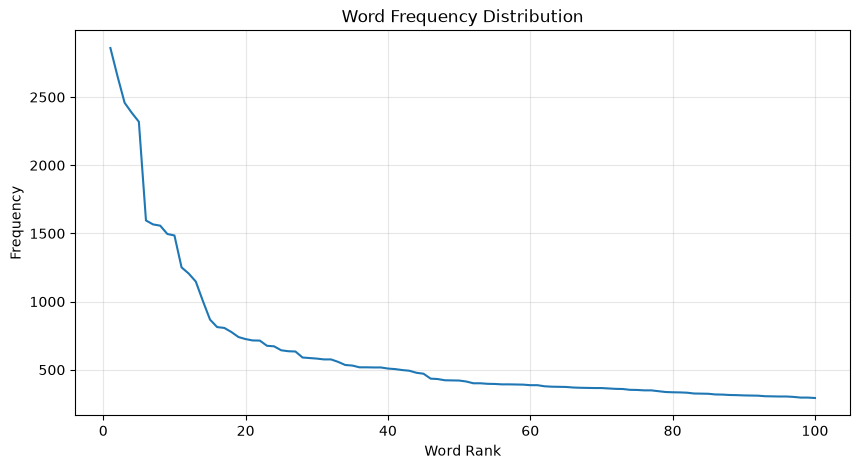

In [9]:
# Word frequency distribution
frequencies = [count for _, count in word_counts.most_common()]

plt.figure(figsize=(10, 5))
plt.plot(range(1, min(len(frequencies), 100) + 1), frequencies[:100])
plt.xlabel('Word Rank')
plt.ylabel('Frequency')
plt.title('Word Frequency Distribution')
plt.grid(True, alpha=0.3)
plt.show()

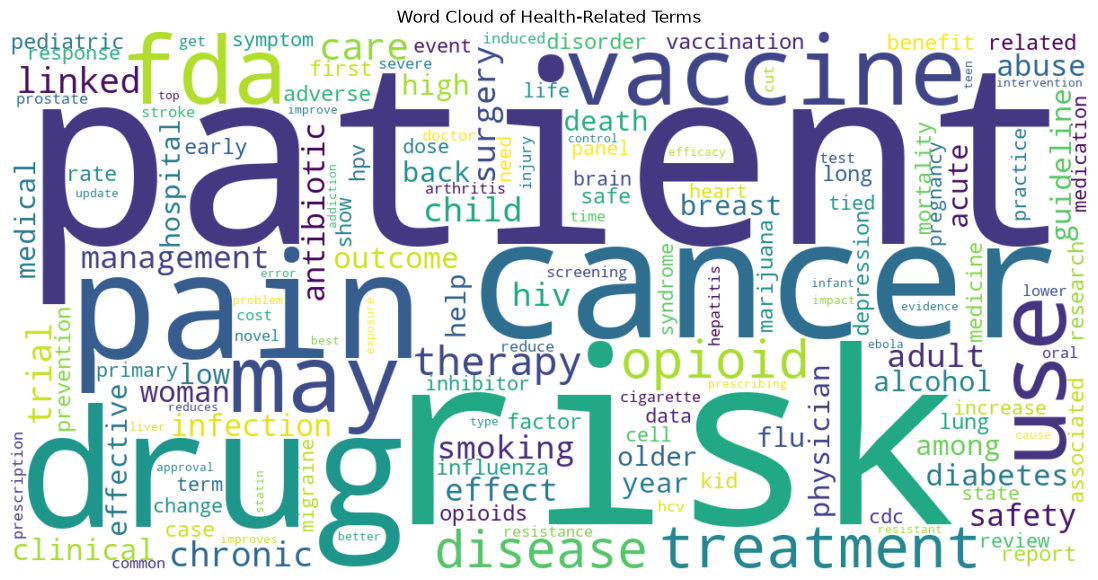

In [10]:
# Word Cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=150,
    collocations=False
).generate_from_frequencies(word_counts)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Health-Related Terms')
plt.show()

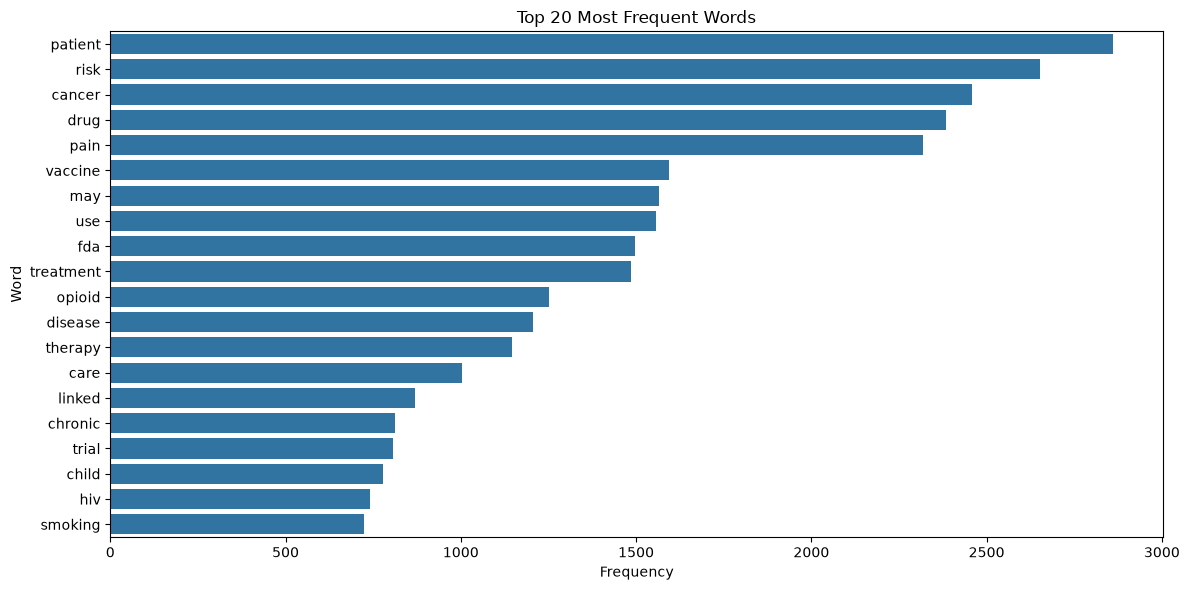

In [11]:
# Top 20 frequent words
TOP_N = 20
top_words = word_counts.most_common(TOP_N)
words = [item[0] for item in top_words]
counts = [item[1] for item in top_words]

plt.figure(figsize=(12, 6))
sns.barplot(x=counts, y=words)
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.title('Top 20 Most Frequent Words')
plt.tight_layout()
plt.show()

# Task 3 – Topic Modelling using LDA



In [12]:
# Convert the cleaned text corpus into a document-term matrix
vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=5,
    max_features=5000,
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(df['Cleaned_Text'].fillna(''))
feature_names = vectorizer.get_feature_names_out()

print('Document-term matrix shape:', X.shape)

Document-term matrix shape: (39405, 5000)


In [13]:
# Train LDA model
NUM_TOPICS = 5

lda_model = LatentDirichletAllocation(
    n_components=NUM_TOPICS,
    random_state=42,
    learning_method='batch',
    max_iter=20
)

lda_model.fit(X)

doc_topic_distribution = lda_model.transform(X)

print('LDA model trained successfully.')

LDA model trained successfully.


### Display the top 5 words for each topic

In [14]:
def display_topics(model, feature_names, n_top_words=5):
    for topic_idx, topic in enumerate(model.components_):
        top_indices = topic.argsort()[:-n_top_words - 1:-1]
        top_terms = [feature_names[i] for i in top_indices]
        print(f'Topic {topic_idx + 1}: {", ".join(top_terms)}')


display_topics(lda_model, feature_names, n_top_words=5)

Topic 1: cancer, vaccine, treatment, therapy, breast
Topic 2: fda, vaccine, drug, opioid, abuse
Topic 3: risk, linked, smoking, may, diabetes
Topic 4: patient, drug, care, hiv, disease
Topic 5: pain, patient, adult, opioid, surgery


In [15]:
# Assign the dominant topic to each document
# Topic numbers are displayed as 1–5 for easier interpretation.
df['Dominant_Topic'] = doc_topic_distribution.argmax(axis=1) + 1

print('Number of documents assigned to each dominant topic:')
display(df['Dominant_Topic'].value_counts().sort_index().rename('Document Count'))

Number of documents assigned to each dominant topic:


Dominant_Topic
1    7137
2    7459
3    8608
4    7843
5    8358
Name: Document Count, dtype: int64

### Visualize LDA Topics using pyLDAvis


In [17]:
pyLDAvis.enable_notebook()

lda_vis = pyLDAvis.lda_model.prepare(
    lda_model,
    X,
    vectorizer,
    mds='tsne'
)

pyLDAvis.display(lda_vis)